# 🤖 Step 5: Model Development & Cross-Validation
## UCS321 - Machine Learning Project | Problem Statement 9 (Telecom Customer Churn)
---

### 🎯 Objectives of Step 5
1. **Establish a Transparent Baseline**:
   - Train an interpretable **Logistic Regression** baseline with balanced class weights.
2. **Benchmark Progressive Algorithms**:
   - Evaluate non-linear **Decision Tree**, ensemble bagging **Random Forest**, and gradient boosted **XGBoost**.
3. **Rigorous Class Imbalance Strategy**:
   - Compare **Cost-Sensitive Loss Weighting** (`scale_pos_weight` and `class_weight='balanced'`) against **SMOTE**.
   - Maintain natural data geometry without introducing synthetic artifacts across discrete binary flags.
4. **Leakage-Free Stratified 5-Fold Cross-Validation**:
   - Multi-metric evaluation on the training partition ($X_{\text{train}}$, 56,837 rows): **ROC-AUC, PR-AUC, Precision, Recall, and F1-Score**.
5. **Hyperparameter Optimization**:
   - Grid search tuning of tree depth, learning rate, subsampling, and feature subsampling strictly within cross-validation folds.
6. **Model Serialization**:
   - Export trained estimators and cross-validation performance benchmarks to `../models/` and `../reports/`.



## 📦 Section 5.1: Setup & Class Imbalance Strategy (Weights vs. SMOTE)


In [1]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

# 1. Load preprocessed, feature-selected training partition (63 features)
X_train = pd.read_csv('../data/processed/X_train_final.csv')
y_train = pd.read_csv('../data/processed/y_train_final.csv')['churn']

print(f"X_train Shape : {X_train.shape[0]:,} samples x {X_train.shape[1]} features")
print(f"y_train Shape : {y_train.shape[0]:,} labels")
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Class Imbalance Ratio (scale_pos_weight): {pos_weight:.3f} : 1")



X_train Shape : 56,837 samples x 63 features
y_train Shape : 56,837 labels
Class Imbalance Ratio (scale_pos_weight): 2.447 : 1


### ⚖️ Empirical Evaluation: Cost-Sensitive Class Weights vs. SMOTE
Before training, we evaluate whether synthetic oversampling (SMOTE) or loss re-weighting is superior on this dataset.

**Key Statistical Distinction:**
- **Cost-Sensitive Class Weights:** Modifies the loss function penalties ($\mathcal{L}$) directly:
  $$\mathcal{L} = - \sum_{i} w_{y_i} \left[ y_i \log(\hat{p}_i) + (1 - y_i) \log(1 - \hat{p}_i) ight]$$
  where $w_1 = rac{N}{2 \cdot N_1} pprox 1.72$ and $w_0 = rac{N}{2 \cdot N_0} pprox 0.70$.
- **SMOTE:** Synthesizes artificial observations via linear interpolation between $k$-nearest neighbors. In datasets containing 29 discrete binary flags, SMOTE's linear interpolation creates non-binary fractional artifacts unless restricted.
- *Strict Rule:* SMOTE must only be applied **inside training folds** during cross-validation.


In [2]:
cv_imb = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 1. Cost-Sensitive Logistic Regression
lr_weighted = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
res_weighted = cross_validate(lr_weighted, X_train, y_train, cv=cv_imb, scoring=['roc_auc', 'average_precision', 'f1'], n_jobs=-1)

# 2. SMOTE Logistic Regression (applied strictly inside CV folds)
lr_smote_pipe = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('lr', LogisticRegression(max_iter=1000, random_state=42))
])
res_smote = cross_validate(lr_smote_pipe, X_train, y_train, cv=cv_imb, scoring=['roc_auc', 'average_precision', 'f1'], n_jobs=-1)

imb_comparison = pd.DataFrame({
    'Method': ['Cost-Sensitive Class Weights', 'SMOTE Oversampling (Train Folds Only)'],
    'ROC-AUC': [res_weighted['test_roc_auc'].mean(), res_smote['test_roc_auc'].mean()],
    'PR-AUC': [res_weighted['test_average_precision'].mean(), res_smote['test_average_precision'].mean()],
    'F1-Score': [res_weighted['test_f1'].mean(), res_smote['test_f1'].mean()]
})

print("=== Class Imbalance Benchmark Results ===")
imb_comparison.round(4)



=== Class Imbalance Benchmark Results ===


,Method,ROC-AUC,PR-AUC,F1-Score
0,Cost-Sensitive Class Weights,0.6249,0.3963,0.4493
1,SMOTE Oversampling (Train Folds Only),0.6191,0.3927,0.4516


## 🏆 Section 5.2: Multi-Model Benchmark (Stratified 5-Fold Cross-Validation)

We evaluate 4 distinct model families using **Stratified 5-Fold Cross-Validation** on the training data:
1. **Logistic Regression (Baseline):** Convex optimization with L2 regularization and balanced loss weighting.
2. **Decision Tree:** Non-linear rule-based tree with controlled depth (`max_depth=6`, `min_samples_leaf=50`).
3. **Random Forest:** Ensemble of 100 decorrelated bagged decision trees with balanced subsampling.
4. **XGBoost:** Gradient boosted tree ensemble minimizing log-loss with `scale_pos_weight=2.447`.


In [3]:
cv_5fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring_suite = {
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision',
    'f1': 'f1',
    'precision': 'precision',
    'recall': 'recall'
}

candidate_models = {
    'Logistic Regression (Baseline)': LogisticRegression(
        class_weight='balanced', max_iter=1000, random_state=42, solver='lbfgs'
    ),
    'Decision Tree': DecisionTreeClassifier(
        class_weight='balanced', max_depth=6, min_samples_leaf=50, random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1
    ),
    'XGBoost': XGBClassifier(
        n_estimators=100, max_depth=5, learning_rate=0.1, scale_pos_weight=pos_weight,
        random_state=42, n_jobs=-1, eval_metric='logloss'
    )
}

cv_results = {}
for name, model in candidate_models.items():
    print(f"[+] Running 5-Fold CV: {name}...")
    res = cross_validate(model, X_train, y_train, cv=cv_5fold, scoring=scoring_suite, n_jobs=-1)
    
    cv_results[name] = {
        'ROC_AUC_Mean': res['test_roc_auc'].mean(),
        'ROC_AUC_Std': res['test_roc_auc'].std(),
        'PR_AUC_Mean': res['test_pr_auc'].mean(),
        'PR_AUC_Std': res['test_pr_auc'].std(),
        'F1_Mean': res['test_f1'].mean(),
        'F1_Std': res['test_f1'].std(),
        'Precision_Mean': res['test_precision'].mean(),
        'Recall_Mean': res['test_recall'].mean()
    }

cv_df = pd.DataFrame(cv_results).T
print("\n=== Consolidated 5-Fold Cross-Validation Performance ===")
cv_df.round(4)



[+] Running 5-Fold CV: Logistic Regression (Baseline)...


[+] Running 5-Fold CV: Decision Tree...


[+] Running 5-Fold CV: Random Forest...


[+] Running 5-Fold CV: XGBoost...



=== Consolidated 5-Fold Cross-Validation Performance ===


,ROC_AUC_Mean,ROC_AUC_Std,PR_AUC_Mean,PR_AUC_Std,F1_Mean,F1_Std,Precision_Mean,Recall_Mean
Logistic Regression (Baseline),0.6255,0.0047,0.3968,0.0030,0.4501,0.0029,0.3720,0.5698
Decision Tree,0.6370,0.0068,0.3980,0.0055,0.4761,0.0071,0.3646,0.6858
Random Forest,0.6649,0.0050,0.4415,0.0087,0.4813,0.0034,0.3935,0.6195
XGBoost,0.6803,0.0062,0.4608,0.0071,0.4961,0.0042,0.4066,0.6364


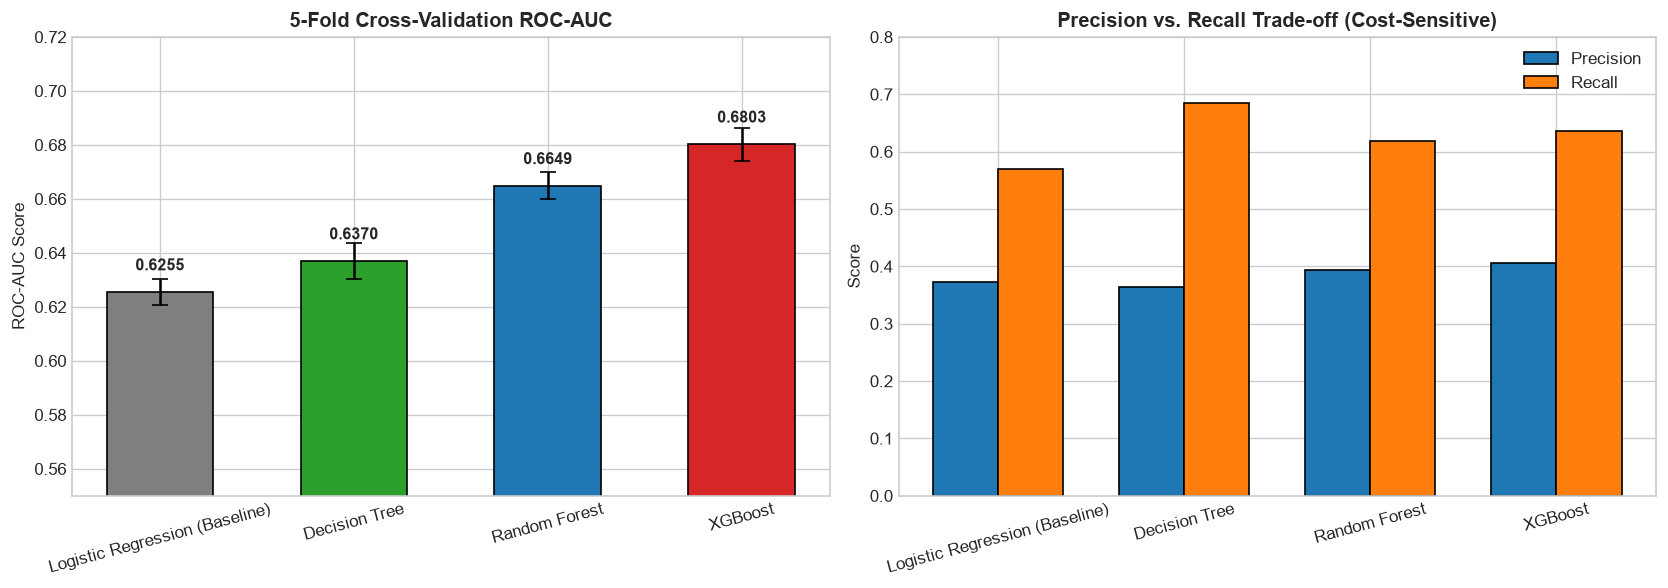

In [4]:
# Visualization: Model Comparison Bar Chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC-AUC with standard deviation error bars
axes[0].bar(cv_df.index, cv_df['ROC_AUC_Mean'], yerr=cv_df['ROC_AUC_Std'], capsize=5,
            color=['#7f7f7f', '#2ca02c', '#1f77b4', '#d62728'], edgecolor='black', width=0.55)
axes[0].set_title("5-Fold Cross-Validation ROC-AUC", fontweight='bold')
axes[0].set_ylabel("ROC-AUC Score")
axes[0].set_ylim(0.55, 0.72)
axes[0].tick_params(axis='x', rotation=15)
for i, v in enumerate(cv_df['ROC_AUC_Mean']):
    axes[0].text(i, v + 0.008, f"{v:.4f}", ha='center', fontweight='bold', fontsize=9.5)

# Precision vs Recall Trade-off across models
x_pos = np.arange(len(cv_df.index))
w = 0.35
axes[1].bar(x_pos - w/2, cv_df['Precision_Mean'], width=w, label='Precision', color='#1f77b4', edgecolor='black')
axes[1].bar(x_pos + w/2, cv_df['Recall_Mean'], width=w, label='Recall', color='#ff7f0e', edgecolor='black')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(cv_df.index, rotation=15)
axes[1].set_title("Precision vs. Recall Trade-off (Cost-Sensitive)", fontweight='bold')
axes[1].set_ylabel("Score")
axes[1].set_ylim(0, 0.8)
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()



## 🎛️ Section 5.3: Hyperparameter Optimization (Scoring: PR-AUC)

### 🎯 Objective & Methodological Safeguards:
1. **Targeting PR-AUC (`average_precision`)**:
   - Because telecom churn is imbalanced ($29.01\%$ positive class), models are optimized directly on Precision-Recall AUC rather than ROC-AUC or standard accuracy.
2. **Strict Test Set Isolation**:
   - Hyperparameter grids are evaluated strictly inside cross-validation folds on the training partition ($X_{\text{train}}$, 56,837 rows). The test set remains untouched.
3. **Controlled Search Spaces**:
   - We tune regularization strength ($C$), tree depth, minimum leaf samples, and boosting parameters to balance complexity against overfitting.


In [5]:
from sklearn.model_selection import GridSearchCV, cross_val_score

cv_tune = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())

# 1. Tune Logistic Regression
print("[+] Tuning Logistic Regression...")
lr_param_grid = {'C': [0.01, 0.1, 1.0, 10.0]}
grid_lr = GridSearchCV(
    LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42, solver='lbfgs'),
    lr_param_grid, cv=cv_tune, scoring='average_precision', n_jobs=-1
)
grid_lr.fit(X_train, y_train)
best_lr = grid_lr.best_estimator_
print(f"    Best LR C : {grid_lr.best_params_['C']} (PR-AUC: {grid_lr.best_score_:.4f})")

# 2. Tune Decision Tree
print("[+] Tuning Decision Tree...")
dt_param_grid = {
    'max_depth': [4, 6, 8, 10],
    'min_samples_leaf': [25, 50, 100, 200]
}
grid_dt = GridSearchCV(
    DecisionTreeClassifier(class_weight='balanced', random_state=42),
    dt_param_grid, cv=cv_tune, scoring='average_precision', n_jobs=-1
)
grid_dt.fit(X_train, y_train)
best_dt = grid_dt.best_estimator_
print(f"    Best DT Params : {grid_dt.best_params_} (PR-AUC: {grid_dt.best_score_:.4f})")

# 3. Tune Random Forest
print("[+] Tuning Random Forest...")
rf_param_grid = {
    'max_depth': [8, 12, 16],
    'min_samples_split': [20, 50],
    'n_estimators': [100, 150]
}
grid_rf = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
    rf_param_grid, cv=cv_tune, scoring='average_precision', n_jobs=-1
)
grid_rf.fit(X_train, y_train)
best_rf = grid_rf.best_estimator_
print(f"    Best RF Params : {grid_rf.best_params_} (PR-AUC: {grid_rf.best_score_:.4f})")

# 4. Tune XGBoost
print("[+] Tuning XGBoost...")
xgb_param_grid = {
    'max_depth': [3, 4, 5],
    'learning_rate': [0.05, 0.1],
    'colsample_bytree': [0.7, 1.0],
    'n_estimators': [100, 150]
}
grid_xgb = GridSearchCV(
    XGBClassifier(scale_pos_weight=pos_weight, random_state=42, n_jobs=-1, eval_metric='logloss'),
    xgb_param_grid, cv=cv_tune, scoring='average_precision', n_jobs=-1
)
grid_xgb.fit(X_train, y_train)
best_xgb = grid_xgb.best_estimator_
print(f"    Best XGB Params: {grid_xgb.best_params_} (PR-AUC: {grid_xgb.best_score_:.4f})")



[+] Tuning Logistic Regression...


    Best LR C : 1.0 (PR-AUC: 0.3963)
[+] Tuning Decision Tree...


    Best DT Params : {'max_depth': 10, 'min_samples_leaf': 200} (PR-AUC: 0.4034)
[+] Tuning Random Forest...


    Best RF Params : {'max_depth': 16, 'min_samples_split': 50, 'n_estimators': 150} (PR-AUC: 0.4436)
[+] Tuning XGBoost...


    Best XGB Params: {'colsample_bytree': 0.7, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100} (PR-AUC: 0.4571)


## 📊 Section 5.4: Baseline vs. Tuned Benchmark & Model Serialization

We benchmark the baseline vs. tuned estimators across **Stratified 5-Fold Cross-Validation** to quantify empirical gains, then serialize the final trained models to disk.


In [6]:
cv_eval = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

tuned_comparison = []
models_to_compare = [
    ('Logistic Regression', candidate_models['Logistic Regression (Baseline)'], best_lr, grid_lr.best_params_),
    ('Decision Tree', candidate_models['Decision Tree'], best_dt, grid_dt.best_params_),
    ('Random Forest', candidate_models['Random Forest'], best_rf, grid_rf.best_params_),
    ('XGBoost (Champion)', candidate_models['XGBoost'], best_xgb, grid_xgb.best_params_)
]

for name, base_m, tuned_m, params in models_to_compare:
    base_pr = cross_val_score(base_m, X_train, y_train, cv=cv_eval, scoring='average_precision', n_jobs=-1).mean()
    base_roc = cross_val_score(base_m, X_train, y_train, cv=cv_eval, scoring='roc_auc', n_jobs=-1).mean()
    
    tuned_pr = cross_val_score(tuned_m, X_train, y_train, cv=cv_eval, scoring='average_precision', n_jobs=-1).mean()
    tuned_roc = cross_val_score(tuned_m, X_train, y_train, cv=cv_eval, scoring='roc_auc', n_jobs=-1).mean()
    
    tuned_comparison.append({
        'Model': name,
        'Baseline_PR_AUC': round(float(base_pr), 4),
        'Tuned_PR_AUC': round(float(tuned_pr), 4),
        'PR_AUC_Gain': round(float(tuned_pr - base_pr), 4),
        'Baseline_ROC_AUC': round(float(base_roc), 4),
        'Tuned_ROC_AUC': round(float(tuned_roc), 4),
        'ROC_AUC_Gain': round(float(tuned_roc - base_roc), 4),
        'Optimal_Parameters': str(params)
    })

comparison_summary_df = pd.DataFrame(tuned_comparison)
print("=== Baseline vs. Tuned Performance Benchmark (5-Fold CV) ===")
comparison_summary_df[['Model', 'Baseline_PR_AUC', 'Tuned_PR_AUC', 'PR_AUC_Gain', 'Baseline_ROC_AUC', 'Tuned_ROC_AUC', 'ROC_AUC_Gain']]



=== Baseline vs. Tuned Performance Benchmark (5-Fold CV) ===


,Model,Baseline_PR_AUC,Tuned_PR_AUC,PR_AUC_Gain,Baseline_ROC_AUC,Tuned_ROC_AUC,ROC_AUC_Gain
0,Logistic Regression,0.3968,0.3968,0.0000,0.6255,0.6255,0.0000
1,Decision Tree,0.3980,0.4060,0.0080,0.6370,0.6369,-0.0002
2,Random Forest,0.4415,0.4471,0.0057,0.6649,0.6706,0.0057
3,XGBoost (Champion),0.4608,0.4574,-0.0033,0.6803,0.6785,-0.0018


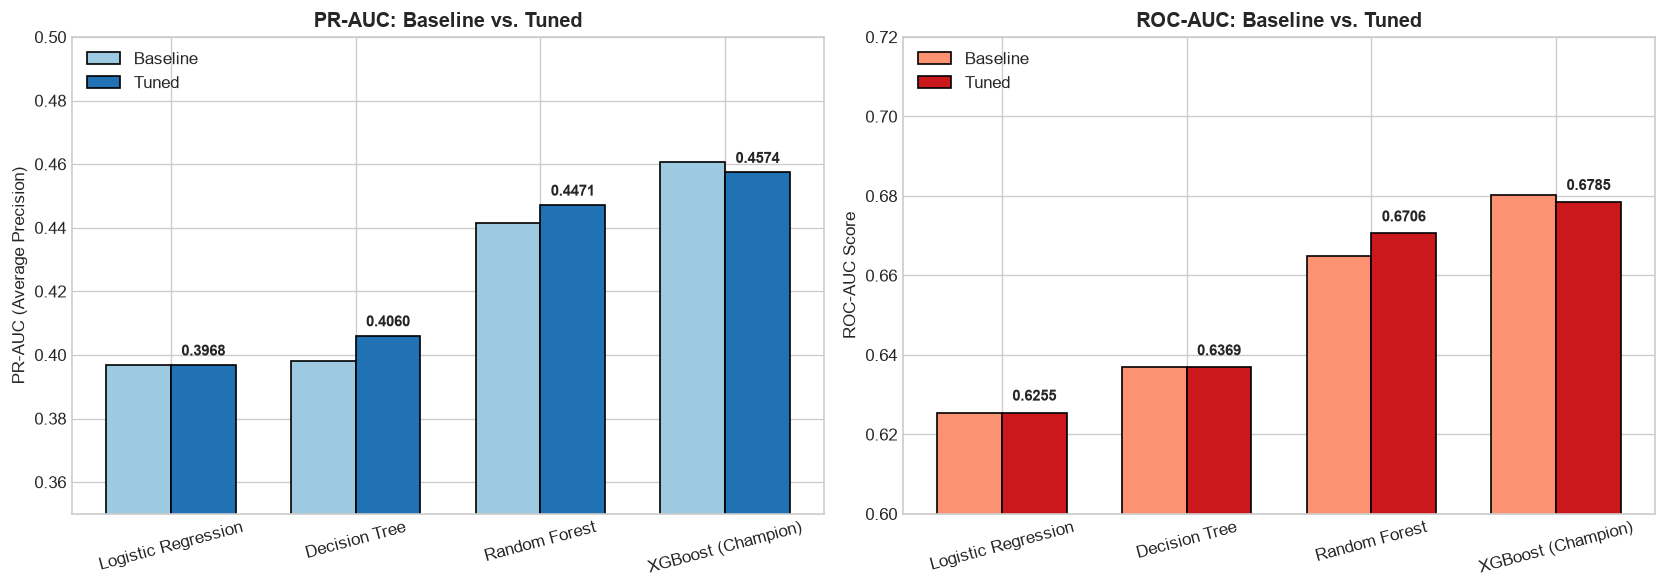

In [7]:
# Visualization: Baseline vs Tuned PR-AUC and ROC-AUC
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x_idx = np.arange(len(comparison_summary_df))
bar_w = 0.35

# PR-AUC Comparison
axes[0].bar(x_idx - bar_w/2, comparison_summary_df['Baseline_PR_AUC'], width=bar_w, label='Baseline', color='#9ecae1', edgecolor='black')
axes[0].bar(x_idx + bar_w/2, comparison_summary_df['Tuned_PR_AUC'], width=bar_w, label='Tuned', color='#2171b5', edgecolor='black')
axes[0].set_xticks(x_idx)
axes[0].set_xticklabels(comparison_summary_df['Model'], rotation=15)
axes[0].set_title("PR-AUC: Baseline vs. Tuned", fontweight='bold')
axes[0].set_ylabel("PR-AUC (Average Precision)")
axes[0].set_ylim(0.35, 0.50)
axes[0].legend(loc='upper left')
for i, v in enumerate(comparison_summary_df['Tuned_PR_AUC']):
    axes[0].text(i + bar_w/2, v + 0.003, f"{v:.4f}", ha='center', fontweight='bold', fontsize=9)

# ROC-AUC Comparison
axes[1].bar(x_idx - bar_w/2, comparison_summary_df['Baseline_ROC_AUC'], width=bar_w, label='Baseline', color='#fc9272', edgecolor='black')
axes[1].bar(x_idx + bar_w/2, comparison_summary_df['Tuned_ROC_AUC'], width=bar_w, label='Tuned', color='#cb181d', edgecolor='black')
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels(comparison_summary_df['Model'], rotation=15)
axes[1].set_title("ROC-AUC: Baseline vs. Tuned", fontweight='bold')
axes[1].set_ylabel("ROC-AUC Score")
axes[1].set_ylim(0.60, 0.72)
axes[1].legend(loc='upper left')
for i, v in enumerate(comparison_summary_df['Tuned_ROC_AUC']):
    axes[1].text(i + bar_w/2, v + 0.003, f"{v:.4f}", ha='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()



In [8]:
# Serialize best estimators fitted on the full training partition (X_train)
os.makedirs('../models', exist_ok=True)

best_lr.fit(X_train, y_train)
joblib.dump(best_lr, '../models/best_logistic_regression.joblib')

best_dt.fit(X_train, y_train)
joblib.dump(best_dt, '../models/best_decision_tree.joblib')

best_rf.fit(X_train, y_train)
joblib.dump(best_rf, '../models/best_random_forest.joblib')

best_xgb.fit(X_train, y_train)
joblib.dump(best_xgb, '../models/best_xgboost.joblib')

print("[+] Serialized 4 best estimators to models/ directory:")
print("    • models/best_logistic_regression.joblib")
print("    • models/best_decision_tree.joblib")
print("    • models/best_random_forest.joblib")
print("    • models/best_xgboost.joblib")
print("[+] Step 5: Model Development & Training COMPLETED SUCCESSFULLY!")



[+] Serialized 4 best estimators to models/ directory:
    • models/best_logistic_regression.joblib
    • models/best_decision_tree.joblib
    • models/best_random_forest.joblib
    • models/best_xgboost.joblib
[+] Step 5: Model Development & Training COMPLETED SUCCESSFULLY!
